
   STOCK MARKET PREDICTION USING LSTM
1. Download Historical Stock Data
2. Display Stock Data and Price Graph
3. Train LSTM Neural Network
4. Display Actual vs Predicted Graph
5. Predict Next Trading Day Price
6. Exit

Enter your choice (1-6): 1

========== DOWNLOAD STOCK DATA ==========
Enter Stock Ticker (default AAPL): AAPL
Enter Start Date (default 2015-01-01): 2015-01-01
Enter End Date (default today): 2024-01-01


Stock data downloaded successfully!
Stock: AAPL
Total Records: 2264
First Date: 2015-01-02 00:00:00
Last Date: 2023-12-29 00:00:00

First Five Records:
                Close
Date                 
2015-01-02  24.171759
2015-01-05  23.490801
2015-01-06  23.493015
2015-01-07  23.822437
2015-01-08  24.737751

   STOCK MARKET PREDICTION USING LSTM
1. Download Historical Stock Data
2. Display Stock Data and Price Graph
3. Train LSTM Neural Network
4. Display Actual vs Predicted Graph
5. Predict Next Trading Day Price
6. Exit

Enter your choice (1-6): 2

========== STOCK DATA

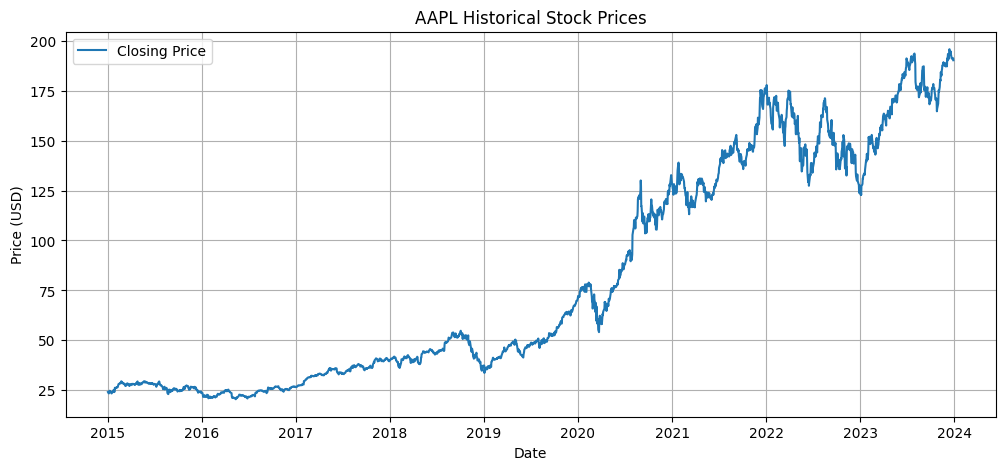


   STOCK MARKET PREDICTION USING LSTM
1. Download Historical Stock Data
2. Display Stock Data and Price Graph
3. Train LSTM Neural Network
4. Display Actual vs Predicted Graph
5. Predict Next Trading Day Price
6. Exit


In [ ]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import yfinance as yf

from sklearn.preprocessing import MinMaxScaler

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout, Input


# ==========================================
# 1. GLOBAL VARIABLES
# ==========================================

df = None
prices = None
scaler = None
model = None

X_train = None
y_train = None
X_test = None
y_test = None

predictions = None
actual_prices = None
history = None

ticker = ""
train_size = 0
LOOKBACK_DAYS = 60


# ==========================================
# 2. DOWNLOAD STOCK DATA
# ==========================================

def download_stock_data():

    global df, prices, ticker

    print("\n========== DOWNLOAD STOCK DATA ==========")

    ticker = input(
        "Enter Stock Ticker (default AAPL): "
    ).strip().upper() or "AAPL"

    start_date = input(
        "Enter Start Date (default 2015-01-01): "
    ).strip() or "2015-01-01"

    end_date = input(
        "Enter End Date (default today): "
    ).strip() or (
        pd.Timestamp.today() + pd.Timedelta(days=1)
    ).strftime("%Y-%m-%d")

    try:

        print("\nDownloading stock data...")

        df = yf.download(
            ticker,
            start=start_date,
            end=end_date,
            auto_adjust=True,
            progress=False
        )

        if df.empty:

            print("No stock data found. Check the ticker and dates.")
            return

        # Handle different yfinance column formats
        close_data = df["Close"]

        if isinstance(close_data, pd.DataFrame):
            close_data = close_data.iloc[:, 0]

        prices = close_data.dropna().to_frame(
            name="Close"
        )

        if len(prices) <= LOOKBACK_DAYS + 20:

            print("Not enough historical data for prediction.")
            df = None
            prices = None
            return

        print("\nStock data downloaded successfully!")

        print("Stock:", ticker)
        print("Total Records:", len(prices))
        print("First Date:", prices.index[0])
        print("Last Date:", prices.index[-1])

        print("\nFirst Five Records:")
        print(prices.head())

    except Exception as e:

        print("\nError downloading data:", e)
        df = None
        prices = None


# ==========================================
# 3. DISPLAY STOCK DATA
# ==========================================

def display_stock_data():

    if prices is None:

        print("\nPlease download stock data first.")
        return

    print("\n========== STOCK DATA INFORMATION ==========")

    print("Stock:", ticker)
    print("Total Records:", len(prices))

    print("\nStatistical Information:")
    print(prices.describe())

    plt.figure(figsize=(12, 5))

    plt.plot(
        prices.index,
        prices["Close"],
        label="Closing Price"
    )

    plt.title(ticker + " Historical Stock Prices")
    plt.xlabel("Date")
    plt.ylabel("Price (USD)")
    plt.legend()
    plt.grid(True)
    plt.show()


# ==========================================
# 4. CREATE SEQUENCES
# ==========================================

def create_sequences(dataset, start_target,
                     end_target, time_steps=60):

    X = []
    y = []

    for i in range(start_target, end_target):

        X.append(
            dataset[i - time_steps:i, 0]
        )

        y.append(
            dataset[i, 0]
        )

    return np.array(X), np.array(y)


# ==========================================
# 5. BUILD AND TRAIN LSTM MODEL
# ==========================================

def train_lstm_model():

    global scaler, model
    global X_train, y_train, X_test, y_test
    global predictions, actual_prices, history
    global train_size

    if prices is None:

        print("\nPlease download stock data first.")
        return

    try:

        print("\n========== LSTM MODEL TRAINING ==========")

        epochs = int(
            input("Enter Epochs (default 20): ") or 20
        )

        if epochs < 1:

            print("Epochs must be at least 1.")
            return

        # Convert prices to NumPy array
        data = prices[["Close"]].values

        # Chronological 80-20 split
        train_size = int(len(data) * 0.8)

        # Fit scaler only on training data
        scaler = MinMaxScaler(
            feature_range=(0, 1)
        )

        scaler.fit(data[:train_size])

        scaled_data = scaler.transform(data)

        # Create training sequences
        X_train, y_train = create_sequences(
            scaled_data,
            LOOKBACK_DAYS,
            train_size,
            LOOKBACK_DAYS
        )

        # Create testing sequences
        X_test, y_test = create_sequences(
            scaled_data,
            train_size,
            len(scaled_data),
            LOOKBACK_DAYS
        )

        # Reshape data for LSTM
        X_train = X_train.reshape(
            X_train.shape[0],
            X_train.shape[1],
            1
        )

        X_test = X_test.reshape(
            X_test.shape[0],
            X_test.shape[1],
            1
        )

        print("\nTraining Records:", len(X_train))
        print("Testing Records:", len(X_test))

        # Build LSTM architecture
        model = Sequential([

            Input(shape=(LOOKBACK_DAYS, 1)),

            LSTM(
                units=50,
                return_sequences=True
            ),

            Dropout(0.2),

            LSTM(
                units=50,
                return_sequences=False
            ),

            Dropout(0.2),

            Dense(
                units=25,
                activation="relu"
            ),

            Dense(
                units=1
            )
        ])

        # Compile model
        model.compile(
            optimizer="adam",
            loss="mean_squared_error"
        )

        print("\nModel Architecture:")
        model.summary()

        # Train model
        print("\nTraining Neural Network...")

        history = model.fit(
            X_train,
            y_train,
            epochs=epochs,
            batch_size=32,
            validation_split=0.1,
            shuffle=False,
            verbose=1
        )

        print("\nModel Training Completed!")

        # Predict test data
        scaled_predictions = model.predict(
            X_test,
            verbose=0
        )

        # Convert values back to original price
        predictions = scaler.inverse_transform(
            scaled_predictions
        )

        actual_prices = scaler.inverse_transform(
            y_test.reshape(-1, 1)
        )

        print("\nModel trained successfully!")

    except Exception as e:

        print("\nTraining Error:", e)


# ==========================================
# 6. PLOT ACTUAL VS PREDICTED PRICES
# ==========================================

def plot_predictions():

    if predictions is None or actual_prices is None:

        print("\nPlease train the model first.")
        return

    test_dates = prices.index[train_size:]

    plt.figure(figsize=(13, 6))

    plt.plot(
        test_dates,
        actual_prices.flatten(),
        label="Actual Stock Price",
        color="black"
    )

    plt.plot(
        test_dates,
        predictions.flatten(),
        label="Predicted Stock Price",
        color="green"
    )

    plt.title(
        ticker + " Stock Price Prediction Using LSTM"
    )

    plt.xlabel("Date")
    plt.ylabel("Price (USD)")

    plt.legend()
    plt.grid(True)
    plt.show()

    # Plot training and validation loss
    plt.figure(figsize=(8, 4))

    plt.plot(
        history.history["loss"],
        label="Training Loss"
    )

    plt.plot(
        history.history["val_loss"],
        label="Validation Loss"
    )

    plt.title("LSTM Model Training Loss")
    plt.xlabel("Epoch")
    plt.ylabel("Mean Squared Error")

    plt.legend()
    plt.grid(True)
    plt.show()


# ==========================================
# 7. PREDICT NEXT TRADING DAY PRICE
# ==========================================

def predict_next_day():

    if model is None or scaler is None:

        print("\nPlease train the model first.")
        return

    try:

        # Take the latest 60 trading days
        last_60_days = prices[
            ["Close"]
        ].values[-LOOKBACK_DAYS:]

        # Scale the data
        scaled_last_60 = scaler.transform(
            last_60_days
        )

        # Reshape for LSTM
        X_next = scaled_last_60.reshape(
            1,
            LOOKBACK_DAYS,
            1
        )

        # Predict next price
        scaled_prediction = model.predict(
            X_next,
            verbose=0
        )

        predicted_price = scaler.inverse_transform(
            scaled_prediction
        )[0][0]

        last_price = prices["Close"].iloc[-1]

        print("\n========== NEXT DAY PREDICTION ==========")

        print(
            "Last Available Closing Price: $",
            round(last_price, 2)
        )

        print(
            "Predicted Next Trading Day Price: $",
            round(predicted_price, 2)
        )

        # Indicative price direction
        if predicted_price > last_price * 1.001:

            print("Predicted Direction: UP")

        elif predicted_price < last_price * 0.999:

            print("Predicted Direction: DOWN")

        else:

            print("Predicted Direction: NEARLY STABLE")

    except Exception as e:

        print("\nPrediction Error:", e)


# ==========================================
# 8. MAIN MENU
# ==========================================

while True:

    print("\n==========================================")
    print("   STOCK MARKET PREDICTION USING LSTM")
    print("==========================================")

    print("1. Download Historical Stock Data")
    print("2. Display Stock Data and Price Graph")
    print("3. Train LSTM Neural Network")
    print("4. Display Actual vs Predicted Graph")
    print("5. Predict Next Trading Day Price")
    print("6. Exit")

    choice = input("\nEnter your choice (1-6): ")

    if choice == "1":

        download_stock_data()

    elif choice == "2":

        display_stock_data()

    elif choice == "3":

        train_lstm_model()

    elif choice == "4":

        plot_predictions()

    elif choice == "5":

        predict_next_day()

    elif choice == "6":

        print("\nExiting Stock Market Prediction Program. Thank you!")
        break

    else:

        print("\nInvalid choice! Please select from 1 to 6.")
